In [11]:

from pathlib import Path
import sys
import torch
import pandas as pd
import matplotlib.pyplot as plt

# Project directories
PROJECT_DIR = Path(
    r"C:\Users\rajva\Desktop\image-captioning Project"
)
NOTEBOOK_DIR = PROJECT_DIR / "notebook"

# Phase 5 output directory
PHASE5_DIR = NOTEBOOK_DIR / "phase5_outputs"

# Phase 6 output directory
PHASE6_DIR = NOTEBOOK_DIR / "phase6_outputs"
PHASE6_DIR.mkdir(parents=True, exist_ok=True)

print("Python executable:", sys.executable)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Project directory exists:", PROJECT_DIR.exists())
print("Notebook directory exists:", NOTEBOOK_DIR.exists())
print("Phase 5 outputs exist:", PHASE5_DIR.exists())
print("Phase 6 outputs:", PHASE6_DIR)


Python executable: C:\Users\rajva\anaconda3\envs\image_captioning\python.exe
PyTorch version: 2.13.0+cpu
CUDA available: False
Project directory exists: True
Notebook directory exists: True
Phase 5 outputs exist: True
Phase 6 outputs: C:\Users\rajva\Desktop\image-captioning Project\notebook\phase6_outputs


In [4]:

from pathlib import Path
import sys
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Project paths
PROJECT_DIR = Path(
    r"C:\Users\rajva\Desktop\image-captioning Project"
)
NOTEBOOK_DIR = PROJECT_DIR / "notebook"
PHASE5_DIR = NOTEBOOK_DIR / "phase5_outputs"
PHASE6_DIR = NOTEBOOK_DIR / "phase6_outputs"

# Create output directory if it does not exist
PHASE6_DIR.mkdir(parents=True, exist_ok=True)

# Recorded evaluation metrics
baseline_metrics = {
    "BLEU-1": 0.4704,
    "BLEU-2": 0.3090,
    "BLEU-3": 0.1942,
    "BLEU-4": 0.1247,
    "METEOR": 0.3483,
    "ROUGE-L": 0.3821,
}

vit_metrics = {
    "BLEU-1": 0.5241,
    "BLEU-2": 0.3615,
    "BLEU-3": 0.2409,
    "BLEU-4": 0.1583,
    "METEOR": 0.4055,
    "ROUGE-L": 0.4149,
}

print("Python version:", platform.python_version())
print("Python executable:", sys.executable)
print("\nProject directory exists:", PROJECT_DIR.exists())
print("Phase 5 directory exists:", PHASE5_DIR.exists())
print("Phase 6 output directory:", PHASE6_DIR)

print("\nPhase 5 output files:")
if PHASE5_DIR.exists():
    for file in sorted(PHASE5_DIR.iterdir()):
        print(" -", file.name)
else:
    print("Phase 5 folder not found. Check PROJECT_DIR.")

print("\nSetup complete.")


Python version: 3.13.15
Python executable: C:\Users\rajva\anaconda3\envs\image_captioning\python.exe

Project directory exists: True
Phase 5 directory exists: True
Phase 6 output directory: C:\Users\rajva\Desktop\image-captioning Project\notebook\phase6_outputs

Phase 5 output files:
 - attention_boy_toy_fresh.png
 - confidence_distribution.png
 - lowest_confidence_captions.png
 - phase5_error_analysis.csv
 - phase5_summary.txt
 - verified_visual_error_cases.csv
 - word_attention_visualization.png
 - word_confidence_captions.csv
 - word_confidence_tokens.csv

Setup complete.


In [5]:

# Build comparison table from existing evaluation results

comparison_df = pd.DataFrame({
    "Metric": list(baseline_metrics.keys()),
    "ResNet50 + LSTM": list(baseline_metrics.values()),
    "ViT + Transformer": list(vit_metrics.values()),
})

comparison_df["Absolute Improvement"] = (
    comparison_df["ViT + Transformer"]
    - comparison_df["ResNet50 + LSTM"]
)

comparison_df["Relative Improvement (%)"] = (
    comparison_df["Absolute Improvement"]
    / comparison_df["ResNet50 + LSTM"]
    * 100
)

# Display formatted results
display(
    comparison_df.style.format({
        "ResNet50 + LSTM": "{:.4f}",
        "ViT + Transformer": "{:.4f}",
        "Absolute Improvement": "{:+.4f}",
        "Relative Improvement (%)": "{:+.2f}%"
    }).set_caption("Phase 6: Model Performance Comparison")
)

# Save results for the M.Tech report
comparison_csv = PHASE6_DIR / "model_comparison.csv"
comparison_df.to_csv(comparison_csv, index=False)

print("\nComparison saved to:", comparison_csv)


,Metric,ResNet50 + LSTM,ViT + Transformer,Absolute Improvement,Relative Improvement (%)
0,BLEU-1,0.4704,0.5241,+0.0537,+11.42%
1,BLEU-2,0.3090,0.3615,+0.0525,+16.99%
2,BLEU-3,0.1942,0.2409,+0.0467,+24.05%
3,BLEU-4,0.1247,0.1583,+0.0336,+26.94%
4,METEOR,0.3483,0.4055,+0.0572,+16.42%
5,ROUGE-L,0.3821,0.4149,+0.0328,+8.58%



Comparison saved to: C:\Users\rajva\Desktop\image-captioning Project\notebook\phase6_outputs\model_comparison.csv


## Visualize model performance

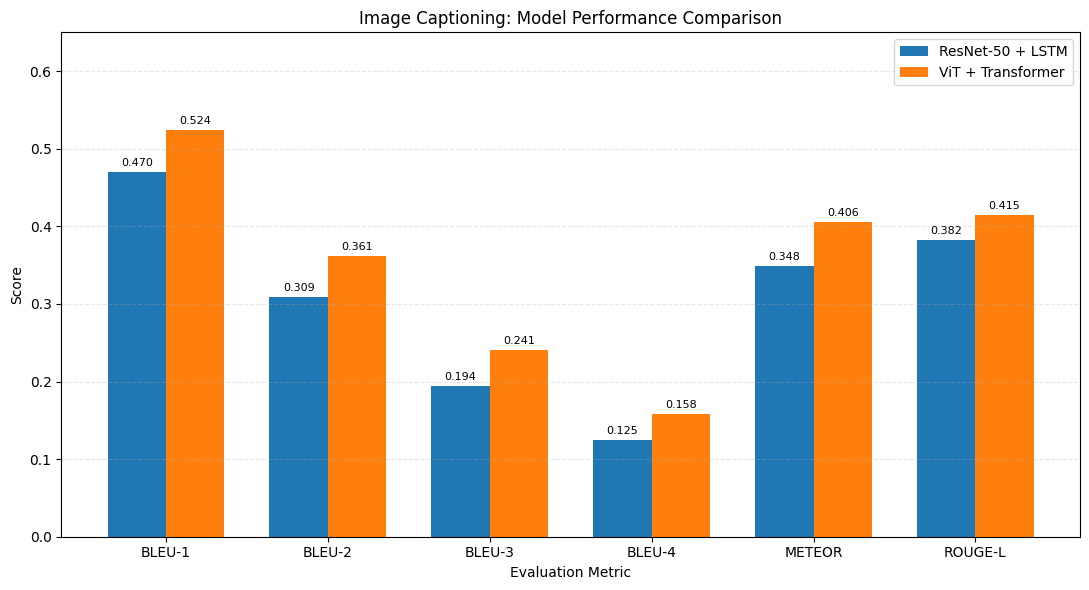

Chart saved to: C:\Users\rajva\Desktop\image-captioning Project\notebook\phase6_outputs\model_performance_comparison.png


In [6]:

# Phase 6: Model performance visualization

metrics = comparison_df["Metric"]
x = np.arange(len(metrics))
width = 0.36

fig, ax = plt.subplots(figsize=(11, 6))

bars1 = ax.bar(
    x - width / 2,
    comparison_df["ResNet50 + LSTM"],
    width,
    label="ResNet-50 + LSTM"
)

bars2 = ax.bar(
    x + width / 2,
    comparison_df["ViT + Transformer"],
    width,
    label="ViT + Transformer"
)

ax.set_title("Image Captioning: Model Performance Comparison")
ax.set_xlabel("Evaluation Metric")
ax.set_ylabel("Score")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 0.65)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)

ax.bar_label(bars1, fmt="%.3f", padding=3, fontsize=8)
ax.bar_label(bars2, fmt="%.3f", padding=3, fontsize=8)

plt.tight_layout()

chart_path = PHASE6_DIR / "model_performance_comparison.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved to:", chart_path)


## Calculate metric-wise improvements

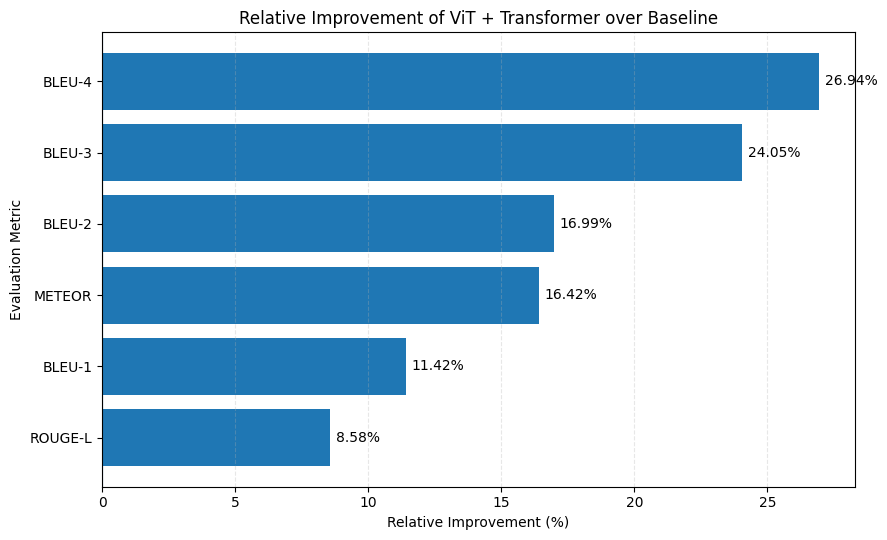

Improvement chart saved: C:\Users\rajva\Desktop\image-captioning Project\notebook\phase6_outputs\relative_metric_improvements.png
Improvement table saved: C:\Users\rajva\Desktop\image-captioning Project\notebook\phase6_outputs\relative_metric_improvements.csv


In [7]:

# Phase 6: Relative improvement analysis

improvement_df = comparison_df[
    ["Metric", "Relative Improvement (%)"]
].copy()

improvement_df = improvement_df.sort_values(
    "Relative Improvement (%)",
    ascending=True
)

fig, ax = plt.subplots(figsize=(9, 5.5))

bars = ax.barh(
    improvement_df["Metric"],
    improvement_df["Relative Improvement (%)"]
)

ax.set_title("Relative Improvement of ViT + Transformer over Baseline")
ax.set_xlabel("Relative Improvement (%)")
ax.set_ylabel("Evaluation Metric")
ax.axvline(0, linewidth=0.8)
ax.grid(axis="x", linestyle="--", alpha=0.3)

ax.bar_label(bars, fmt="%.2f%%", padding=4)
plt.tight_layout()

improvement_chart_path = (
    PHASE6_DIR / "relative_metric_improvements.png"
)

plt.savefig(
    improvement_chart_path,
    dpi=300,
    bbox_inches="tight"
)
plt.show()

improvement_csv_path = (
    PHASE6_DIR / "relative_metric_improvements.csv"
)
improvement_df.to_csv(improvement_csv_path, index=False)

print("Improvement chart saved:", improvement_chart_path)
print("Improvement table saved:", improvement_csv_path)


## 5: Inspect existing checkpoints and cached features

In [8]:

# Phase 6: Locate existing checkpoints and cached features

search_roots = [
    PROJECT_DIR,
    NOTEBOOK_DIR,
]

candidate_names = {
    "best_baseline_model.pth",
    "best_vit_transformer.pth",
    "train_features.pt",
    "val_features.pt",
    "test_features.pt",
}

found_files = {}

for root in search_roots:
    if not root.exists():
        continue

    for path in root.rglob("*"):
        if path.is_file() and (
            path.name in candidate_names
            or path.suffix.lower() in {".ipynb", ".pth", ".pt"}
        ):
            # Avoid duplicate paths
            found_files[str(path.resolve())] = path

print("Existing model checkpoints, cached features, and notebooks")
print("=" * 65)

for path in sorted(found_files.values(), key=lambda p: str(p).lower()):
    size_mb = path.stat().st_size / (1024 ** 2)
    print(f"{path.relative_to(PROJECT_DIR)} | {size_mb:.2f} MB")

print("\nCheckpoint verification")
print("=" * 65)

for name in [
    "best_baseline_model.pth",
    "best_vit_transformer.pth",
]:
    matches = [
        p for p in found_files.values()
        if p.name == name
    ]
    print(f"{name}: {'FOUND' if matches else 'NOT FOUND'}")

print("\nFeature cache verification")
print("=" * 65)

for name in [
    "train_features.pt",
    "val_features.pt",
    "test_features.pt",
]:
    matches = [
        p for p in found_files.values()
        if p.name == name
    ]
    print(f"{name}: {'FOUND' if matches else 'NOT FOUND'}")


Existing model checkpoints, cached features, and notebooks
notebook\.ipynb_checkpoints\01_dataset_exploration-checkpoint.ipynb | 0.75 MB
notebook\.ipynb_checkpoints\baseline_cnn_lstm-checkpoint.ipynb | 0.56 MB
notebook\.ipynb_checkpoints\Phase 6_Model Comparison and Ablation-checkpoint.ipynb | 0.11 MB
notebook\.ipynb_checkpoints\Phase3_ViT_Transformer-checkpoint.ipynb | 2.49 MB
notebook\.ipynb_checkpoints\Phase4_Hallucination_Visual_Consistency-checkpoint.ipynb | 0.46 MB
notebook\.ipynb_checkpoints\Phase5_Analysis-checkpoint.ipynb | 0.13 MB
notebook\01_dataset_exploration.ipynb | 0.75 MB
notebook\baseline_cnn_lstm.ipynb | 0.56 MB
notebook\cached_features\test_features.pt | 40.51 MB
notebook\cached_features\train_features.pt | 243.07 MB
notebook\cached_features\val_features.pt | 40.51 MB
notebook\checkpoints\best_baseline_model.pth | 136.34 MB
notebook\checkpoints_vit_transformer\best_vit_transformer.pth | 109.50 MB
notebook\Phase 6_Model Comparison and Ablation.ipynb | 0.11 MB
notebook

## Verify the ViT feature cache

In [9]:

import sys
import subprocess
from pathlib import Path

print("Current notebook Python:")
print(sys.executable)

env_python = (
    Path.home()
    / "anaconda3"
    / "envs"
    / "image_captioning"
    / "python.exe"
)

print("\nExpected project Python:")
print(env_python)
print("Environment exists:", env_python.exists())

if env_python.exists():
    result = subprocess.run(
        [
            str(env_python),
            "-c",
            "import sys; print('Python:', sys.executable); "
            "import torch; print('PyTorch:', torch.__version__)"
        ],
        capture_output=True,
        text=True
    )

    print("\nEnvironment check:")
    print(result.stdout)

    if result.stderr:
        print(result.stderr)


Current notebook Python:
C:\Users\rajva\anaconda3\envs\image_captioning\python.exe

Expected project Python:
C:\Users\rajva\anaconda3\envs\image_captioning\python.exe
Environment exists: True

Environment check:
Python: C:\Users\rajva\anaconda3\envs\image_captioning\python.exe
PyTorch: 2.13.0+cpu



In [19]:

# # Phase 6: Inspect ViT cached feature files safely

# VIT_CACHE_DIR = NOTEBOOK_DIR / "vit_cached_features"

# vit_cache_files = [
#     VIT_CACHE_DIR / "val_vit_features.pt",
#     VIT_CACHE_DIR / "test_vit_features.pt",
# ]

# for path in vit_cache_files:
#     print(f"\nFile: {path.name}")
#     print("Exists:", path.exists())

#     if not path.exists():
#         continue

#     print(f"Size: {path.stat().st_size / (1024**2):.2f} MB")

#     try:
#         obj = torch.load(
#             path,
#             map_location="cpu",
#             weights_only=False
#         )

#         print("Object type:", type(obj).__name__)

#         if isinstance(obj, dict):
#             print("Dictionary keys:", list(obj.keys()))

#             for key, value in obj.items():
#                 if isinstance(value, torch.Tensor):
#                     print(
#                         f"  {key}: shape={tuple(value.shape)}, "
#                         f"dtype={value.dtype}"
#                     )
#                 elif isinstance(value, (list, tuple)):
#                     print(
#                         f"  {key}: {type(value).__name__}, "
#                         f"length={len(value)}"
#                     )
#                 else:
#                     print(f"  {key}: {type(value).__name__}")

#         elif isinstance(obj, torch.Tensor):
#             print("Tensor shape:", tuple(obj.shape))

#         del obj

#     except Exception as exc:
#         print("Could not inspect file:", repr(exc))


In [13]:

# Phase 6: Compact inspection of ViT feature caches

for path in vit_cache_files:
    print(f"\n{'=' * 50}")
    print("File:", path.name)

    if not path.exists():
        print("Status: Missing")
        continue

    try:
        cache = torch.load(
            path,
            map_location="cpu",
            weights_only=False
        )

        print("Object type:", type(cache).__name__)

        if isinstance(cache, dict):
            print("Number of image entries:", len(cache))

            # Inspect only the first entry
            if cache:
                first_key = next(iter(cache))
                first_value = cache[first_key]

                print("Example image:", first_key)
                print("Feature object type:", type(first_value).__name__)

                if isinstance(first_value, torch.Tensor):
                    print("Feature shape:", tuple(first_value.shape))
                    print("Feature dtype:", first_value.dtype)

                elif isinstance(first_value, dict):
                    print("Feature dictionary keys:", list(first_value.keys()))

                    for key, value in first_value.items():
                        if isinstance(value, torch.Tensor):
                            print(
                                f"  {key}: shape={tuple(value.shape)}, "
                                f"dtype={value.dtype}"
                            )
                        else:
                            print(f"  {key}: {type(value).__name__}")

        elif isinstance(cache, torch.Tensor):
            print("Tensor shape:", tuple(cache.shape))

        del cache

    except Exception as exc:
        print("Inspection error:", repr(exc))

print("\nCache inspection complete.")



File: val_vit_features.pt
Object type: dict
Number of image entries: 1000
Example image: 1022454332_6af2c1449a.jpg
Feature object type: Tensor
Feature shape: (196, 768)
Feature dtype: torch.float32

File: test_vit_features.pt
Object type: dict
Number of image entries: 1000
Example image: 1056338697_4f7d7ce270.jpg
Feature object type: Tensor
Feature shape: (196, 768)
Feature dtype: torch.float32

Cache inspection complete.


## Check existing model checkpoints and evaluation artifacts

In [14]:

# Phase 6: Locate existing checkpoints and evaluation artifacts

SEARCH_DIRS = [
    NOTEBOOK_DIR / "checkpoints",
    NOTEBOOK_DIR / "cached_features",
    NOTEBOOK_DIR / "vit_cached_features",
    PHASE5_DIR,
]

for folder in SEARCH_DIRS:
    print(f"\n{'=' * 60}")
    print("Folder:", folder)
    print("Exists:", folder.exists())

    if not folder.exists():
        continue

    for path in sorted(folder.iterdir()):
        if path.is_file():
            print(
                f"  {path.name} "
                f"({path.stat().st_size / (1024**2):.2f} MB)"
            )
        elif path.is_dir():
            print(f"  [Folder] {path.name}")

print("\nCheckpoint and artifact inventory complete.")



Folder: C:\Users\rajva\Desktop\image-captioning Project\notebook\checkpoints
Exists: True
  best_baseline_model.pth (136.34 MB)

Folder: C:\Users\rajva\Desktop\image-captioning Project\notebook\cached_features
Exists: True
  test_features.pt (40.51 MB)
  train_features.pt (243.07 MB)
  val_features.pt (40.51 MB)

Folder: C:\Users\rajva\Desktop\image-captioning Project\notebook\vit_cached_features
Exists: True
  test_vit_features.pt (577.30 MB)
  train_vit_features.pt (3463.82 MB)
  val_vit_features.pt (577.30 MB)

Folder: C:\Users\rajva\Desktop\image-captioning Project\notebook\phase5_outputs
Exists: True
  attention_boy_toy_fresh.png (1.42 MB)
  confidence_distribution.png (0.03 MB)
  lowest_confidence_captions.png (0.07 MB)
  phase5_error_analysis.csv (0.43 MB)
  phase5_summary.txt (0.00 MB)
  verified_visual_error_cases.csv (0.00 MB)
  word_attention_visualization.png (1.61 MB)
  word_confidence_captions.csv (0.41 MB)
  word_confidence_tokens.csv (0.69 MB)

Checkpoint and artifact 

In [15]:

# Phase 6: Find model checkpoints and evaluation artifacts

checkpoint_keywords = (
    "best_vit_transformer",
    "vit_transformer",
    "transformer",
    "baseline_model",
)

evaluation_keywords = (
    "evaluation",
    "metrics",
    "bleu",
    "meteor",
    "rouge",
    "comparison",
    "ablation",
)

print("Searching project files...\n")

for path in PROJECT_DIR.rglob("*"):
    if not path.is_file():
        continue

    name = path.name.lower()

    if (
        path.suffix.lower() in {".pth", ".pt", ".ckpt"}
        and any(keyword in name for keyword in checkpoint_keywords)
    ):
        print(
            f"CHECKPOINT: {path.relative_to(PROJECT_DIR)} "
            f"({path.stat().st_size / (1024**2):.2f} MB)"
        )

    elif (
        path.suffix.lower() in {".csv", ".json", ".txt", ".xlsx"}
        and any(keyword in name for keyword in evaluation_keywords)
    ):
        print(f"EVALUATION: {path.relative_to(PROJECT_DIR)}")

print("\nSearch complete.")


Searching project files...

EVALUATION: notebook\baseline_metrics.json
EVALUATION: notebook\vit_transformer_metrics.json
CHECKPOINT: notebook\checkpoints\best_baseline_model.pth (136.34 MB)
CHECKPOINT: notebook\checkpoints_vit_transformer\best_vit_transformer.pth (109.50 MB)
EVALUATION: notebook\phase6_outputs\model_comparison.csv

Search complete.


## Load and validate the recorded metrics

In [16]:

import json

BASELINE_METRICS_PATH = NOTEBOOK_DIR / "baseline_metrics.json"
VIT_METRICS_PATH = NOTEBOOK_DIR / "vit_transformer_metrics.json"
COMPARISON_PATH = PHASE6_DIR / "model_comparison.csv"

for path in [BASELINE_METRICS_PATH, VIT_METRICS_PATH]:
    print(f"\n{'=' * 60}")
    print("Metrics file:", path.name)

    if path.exists():
        with open(path, "r", encoding="utf-8") as file:
            metrics = json.load(file)

        print(json.dumps(metrics, indent=2))
    else:
        print("File not found.")

print(f"\n{'=' * 60}")
print("Existing comparison CSV:", COMPARISON_PATH.exists())

if COMPARISON_PATH.exists():
    existing_comparison = pd.read_csv(COMPARISON_PATH)
    print("Shape:", existing_comparison.shape)
    print("Columns:", list(existing_comparison.columns))
    display(existing_comparison.head(10))



Metrics file: baseline_metrics.json
{
  "model": "ResNet-50 + LSTM",
  "best_epoch": 4,
  "best_validation_loss": 3.240390560429567,
  "BLEU-1": 0.4704,
  "BLEU-2": 0.309,
  "BLEU-3": 0.1942,
  "BLEU-4": 0.1247,
  "METEOR": 0.3483,
  "ROUGE-L": 0.3821
}

Metrics file: vit_transformer_metrics.json
{
  "BLEU-1": 0.5241445006228476,
  "BLEU-2": 0.3614878816932059,
  "BLEU-3": 0.24089649668615595,
  "BLEU-4": 0.1582789001484144,
  "METEOR": 0.40551790524627285,
  "ROUGE-L": 0.41493771126821355
}

Existing comparison CSV: True
Shape: (6, 5)
Columns: ['Metric', 'ResNet50 + LSTM', 'ViT + Transformer', 'Absolute Improvement', 'Relative Improvement (%)']


,Metric,ResNet50 + LSTM,ViT + Transformer,Absolute Improvement,Relative Improvement (%)
0,BLEU-1,0.4704,0.5241,0.0537,11.415816
1,BLEU-2,0.3090,0.3615,0.0525,16.990291
2,BLEU-3,0.1942,0.2409,0.0467,24.047374
3,BLEU-4,0.1247,0.1583,0.0336,26.944667
4,METEOR,0.3483,0.4055,0.0572,16.422624
5,ROUGE-L,0.3821,0.4149,0.0328,8.584140


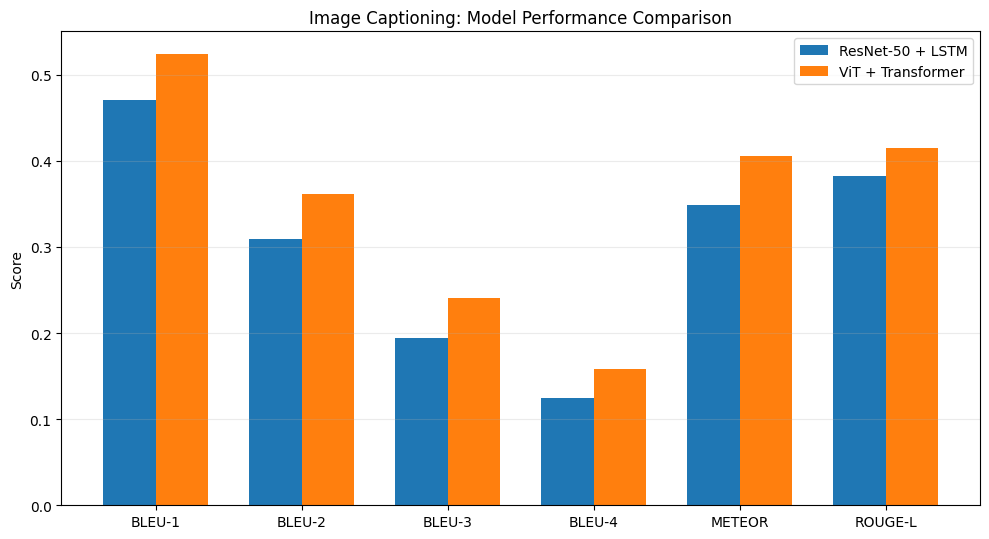

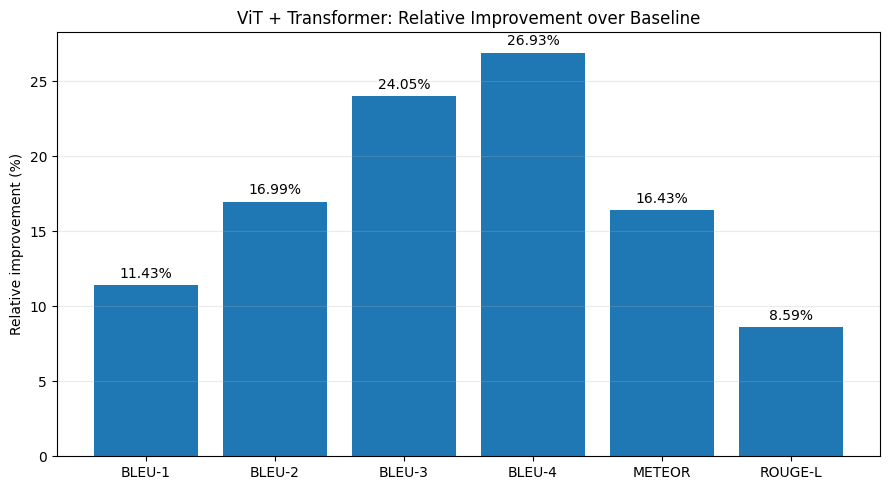

Saved comparison chart: C:\Users\rajva\Desktop\image-captioning Project\notebook\phase6_outputs\model_comparison_chart.png
Saved improvement chart: C:\Users\rajva\Desktop\image-captioning Project\notebook\phase6_outputs\relative_improvement_chart.png


In [17]:

# Phase 6: Model comparison charts

baseline_metrics = json.loads(
    BASELINE_METRICS_PATH.read_text(encoding="utf-8")
)
vit_metrics = json.loads(
    VIT_METRICS_PATH.read_text(encoding="utf-8")
)

metric_names = [
    "BLEU-1", "BLEU-2", "BLEU-3",
    "BLEU-4", "METEOR", "ROUGE-L"
]

baseline_scores = [baseline_metrics[m] for m in metric_names]
vit_scores = [vit_metrics[m] for m in metric_names]

# Chart 1: Side-by-side metric comparison
x = list(range(len(metric_names)))
width = 0.36

fig, ax = plt.subplots(figsize=(10, 5.5))

ax.bar(
    [i - width / 2 for i in x],
    baseline_scores,
    width,
    label="ResNet-50 + LSTM"
)
ax.bar(
    [i + width / 2 for i in x],
    vit_scores,
    width,
    label="ViT + Transformer"
)

ax.set_xticks(x)
ax.set_xticklabels(metric_names)
ax.set_ylabel("Score")
ax.set_title("Image Captioning: Model Performance Comparison")
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()

comparison_chart_path = PHASE6_DIR / "model_comparison_chart.png"
fig.savefig(comparison_chart_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# Chart 2: Relative improvement
relative_improvement = [
    (v - b) / b * 100
    for b, v in zip(baseline_scores, vit_scores)
]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(metric_names, relative_improvement)
ax.bar_label(bars, fmt="%.2f%%", padding=3)
ax.set_ylabel("Relative improvement (%)")
ax.set_title("ViT + Transformer: Relative Improvement over Baseline")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()

improvement_chart_path = PHASE6_DIR / "relative_improvement_chart.png"
fig.savefig(improvement_chart_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved comparison chart:", comparison_chart_path)
print("Saved improvement chart:", improvement_chart_path)


In [18]:

# Phase 6: Save model comparison and improvement summary

comparison_rows = []

for metric, baseline, vit in zip(
    metric_names, baseline_scores, vit_scores
):
    absolute_improvement = vit - baseline
    relative_improvement_pct = (
        absolute_improvement / baseline
    ) * 100

    comparison_rows.append({
        "Metric": metric,
        "ResNet50 + LSTM": baseline,
        "ViT + Transformer": vit,
        "Absolute Improvement": absolute_improvement,
        "Relative Improvement (%)": relative_improvement_pct
    })

comparison_df = pd.DataFrame(comparison_rows)

summary_path = PHASE6_DIR / "model_comparison_summary.csv"
comparison_df.to_csv(summary_path, index=False)

display(
    comparison_df.style.format({
        "ResNet50 + LSTM": "{:.4f}",
        "ViT + Transformer": "{:.4f}",
        "Absolute Improvement": "{:.4f}",
        "Relative Improvement (%)": "{:.2f}%"
    })
)

print("\nSaved:", summary_path)


,Metric,ResNet50 + LSTM,ViT + Transformer,Absolute Improvement,Relative Improvement (%)
0,BLEU-1,0.4704,0.5241,0.0537,11.43%
1,BLEU-2,0.3090,0.3615,0.0525,16.99%
2,BLEU-3,0.1942,0.2409,0.0467,24.05%
3,BLEU-4,0.1247,0.1583,0.0336,26.93%
4,METEOR,0.3483,0.4055,0.0572,16.43%
5,ROUGE-L,0.3821,0.4149,0.0328,8.59%



Saved: C:\Users\rajva\Desktop\image-captioning Project\notebook\phase6_outputs\model_comparison_summary.csv


## Inspect the ViT + Transformer checkpoint

In [20]:

# Phase 6: Inspect the ViT + Transformer checkpoint

VIT_CHECKPOINT_PATH = (
    NOTEBOOK_DIR
    / "checkpoints_vit_transformer"
    / "best_vit_transformer.pth"
)

print("Checkpoint exists:", VIT_CHECKPOINT_PATH.exists())

if VIT_CHECKPOINT_PATH.exists():
    checkpoint = torch.load(
        VIT_CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=False
    )

    print("Checkpoint object type:", type(checkpoint).__name__)

    if isinstance(checkpoint, dict):
        print("\nTop-level keys:")
        for key, value in checkpoint.items():
            if isinstance(value, torch.Tensor):
                print(
                    f"  {key}: Tensor, shape={tuple(value.shape)}, "
                    f"dtype={value.dtype}"
                )
            elif isinstance(value, dict):
                print(f"  {key}: dict with {len(value)} entries")
            else:
                print(f"  {key}: {type(value).__name__}")

        print("\nPotential configuration entries:")
        for key, value in checkpoint.items():
            if any(word in key.lower() for word in (
                "config", "param", "epoch", "loss", "vocab"
            )):
                if isinstance(value, (str, int, float, bool, list, tuple)):
                    print(f"  {key}: {value}")
                elif isinstance(value, dict):
                    print(f"  {key}: {value}")

    else:
        print("Unexpected checkpoint format.")

else:
    print("Checkpoint not found at the expected path.")


Checkpoint exists: True
Checkpoint object type: dict

Top-level keys:
  epoch: int
  model_state_dict: dict with 60 entries
  optimizer_state_dict: dict with 2 entries
  val_loss: float
  vocab_size: int

Potential configuration entries:
  epoch: 4
  val_loss: 3.231365893888149
  vocab_size: 12076


In [22]:
 # Phase 6: Inspect saved Transformer model parameters

vit_state = checkpoint["model_state_dict"]

print("Total parameter tensors:", len(vit_state))
print("\nParameter names and shapes:\n")

for name, tensor in vit_state.items():
    if isinstance(tensor, torch.Tensor):
        print(f"{name:55s} {tuple(tensor.shape)}")

del vit_state


Total parameter tensors: 60

Parameter names and shapes:

embedding.weight                                        (12076, 256)
visual_projection.weight                                (256, 768)
visual_projection.bias                                  (256,)
position_embedding.weight                               (38, 256)
transformer_decoder.layers.0.self_attn.in_proj_weight   (768, 256)
transformer_decoder.layers.0.self_attn.in_proj_bias     (768,)
transformer_decoder.layers.0.self_attn.out_proj.weight  (256, 256)
transformer_decoder.layers.0.self_attn.out_proj.bias    (256,)
transformer_decoder.layers.0.multihead_attn.in_proj_weight (768, 256)
transformer_decoder.layers.0.multihead_attn.in_proj_bias (768,)
transformer_decoder.layers.0.multihead_attn.out_proj.weight (256, 256)
transformer_decoder.layers.0.multihead_attn.out_proj.bias (256,)
transformer_decoder.layers.0.linear1.weight             (1024, 256)
transformer_decoder.layers.0.linear1.bias               (1024,)
transformer_dec

## model definition and evaluation code

In [23]:

# Phase 6: Locate existing model and evaluation code

code_extensions = {".py", ".ipynb"}

search_terms = [
    "transformer_decoder",
    "class Transformer",
    "visual_projection",
    "generate_caption",
    "BLEU-4",
    "corpus_bleu",
    "greedy",
]

print("Searching project code files...\n")

for path in PROJECT_DIR.rglob("*"):
    if not path.is_file() or path.suffix.lower() not in code_extensions:
        continue

    # Skip generated environments and large cache directories
    if any(
        part.lower() in {
            ".git", "__pycache__", "cached_features",
            "vit_cached_features", "checkpoints",
            "checkpoints_vit_transformer"
        }
        for part in path.parts
    ):
        continue

    try:
        content = path.read_text(encoding="utf-8", errors="ignore")
        matched_terms = [
            term for term in search_terms
            if term.lower() in content.lower()
        ]

        if matched_terms:
            print(f"\nFile: {path.relative_to(PROJECT_DIR)}")
            print("Matched:", ", ".join(matched_terms))

    except Exception:
        pass

print("\nCode search complete.")


Searching project code files...


File: notebook\baseline_cnn_lstm.ipynb
Matched: generate_caption, BLEU-4, corpus_bleu

File: notebook\Phase 6_Model Comparison and Ablation.ipynb
Matched: transformer_decoder, visual_projection, BLEU-4

File: notebook\Phase3_ViT_Transformer.ipynb
Matched: transformer_decoder, class Transformer, visual_projection, generate_caption, BLEU-4, corpus_bleu

File: notebook\Phase4_Hallucination_Visual_Consistency.ipynb
Matched: BLEU-4

File: notebook\Phase5_Analysis.ipynb
Matched: transformer_decoder, class Transformer, visual_projection, generate_caption

File: notebook\.ipynb_checkpoints\baseline_cnn_lstm-checkpoint.ipynb
Matched: generate_caption, BLEU-4, corpus_bleu

File: notebook\.ipynb_checkpoints\Phase 6_Model Comparison and Ablation-checkpoint.ipynb
Matched: BLEU-4

File: notebook\.ipynb_checkpoints\Phase3_ViT_Transformer-checkpoint.ipynb
Matched: transformer_decoder, class Transformer, visual_projection, generate_caption, BLEU-4, corpus_bleu

File: n

In [24]:

# Phase 6: Read relevant code from the original Phase 3 notebook

import json

PHASE3_NOTEBOOK = NOTEBOOK_DIR / "Phase3_ViT_Transformer.ipynb"

with open(PHASE3_NOTEBOOK, "r", encoding="utf-8") as file:
    phase3_data = json.load(file)

keywords = [
    "class Transformer",
    "visual_projection",
    "def generate_caption",
    "def evaluate",
    "corpus_bleu",
    "transformer_decoder",
]

print("Notebook:", PHASE3_NOTEBOOK.name)

for index, cell in enumerate(phase3_data.get("cells", [])):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))
    matched = [
        keyword for keyword in keywords
        if keyword.lower() in source.lower()
    ]

    if matched:
        print(f"\n{'=' * 65}")
        print(f"Cell {index} | Matches: {', '.join(matched)}")
        print(source[:9000])

        if len(source) > 9000:
            print("\n[Cell truncated for display]")


Notebook: Phase3_ViT_Transformer.ipynb

Cell 28 | Matches: class Transformer, visual_projection, transformer_decoder
# ============================================================
# PHASE 3 — CELL 16
# Define Transformer Caption Decoder
# ============================================================

import torch
import torch.nn as nn
import math

class TransformerCaptionDecoder(nn.Module):
    def __init__(
        self,
        vocab_size,
        visual_dim=768,
        embed_dim=256,
        num_heads=8,
        num_layers=3,
        feedforward_dim=1024,
        max_length=38,
        dropout=0.1
    ):
        super().__init__()

        self.embed_dim = embed_dim
        self.max_length = max_length

        # Convert token IDs into word embeddings
        self.embedding = nn.Embedding(
            vocab_size, embed_dim, padding_idx=0
        )

        # Project visual patch features into decoder dimension
        self.visual_projection = nn.Linear(
            visual_dim, embed

In [25]:

# Phase 6: Check saved Transformer predictions

PREDICTIONS_PATH = NOTEBOOK_DIR / "vit_transformer_predictions.json"

print("Predictions file:", PREDICTIONS_PATH)
print("Exists:", PREDICTIONS_PATH.exists())

if PREDICTIONS_PATH.exists():
    with open(PREDICTIONS_PATH, "r", encoding="utf-8") as file:
        saved_predictions = json.load(file)

    print("Number of saved predictions:", len(saved_predictions))

    print("\nSample predictions:")
    for image_name, caption in list(saved_predictions.items())[:5]:
        print(f"{image_name}: {caption}")

    print("\nAll prediction values are strings:",
          all(isinstance(caption, str)
              for caption in saved_predictions.values()))
else:
    print("No saved prediction file found; do not regenerate predictions yet.")


Predictions file: C:\Users\rajva\Desktop\image-captioning Project\notebook\vit_transformer_predictions.json
Exists: True
Number of saved predictions: 1000

Sample predictions:
1056338697_4f7d7ce270.jpg: a girl in a blue shirt is jumping into the air.
106490881_5a2dd9b7bd.jpg: a boy in a blue shirt is running in the ocean.
1082379191_ec1e53f996.jpg: a man sitting on a bench in the middle of a boat on a lake.
1084040636_97d9633581.jpg: a white dog is standing in the water with a stick in its mouth.
1096395242_fc69f0ae5a.jpg: a boy in a red shirt is playing with a toy on a chair in the floor.

All prediction values are strings: True


## Validatingg test-image alignment 

In [26]:

# Phase 6: Validate saved predictions against test feature cache

vit_test_cache_path = VIT_CACHE_DIR / "test_vit_features.pt"

vit_test_cache = torch.load(
    vit_test_cache_path,
    map_location="cpu",
    weights_only=False
)

prediction_images = set(saved_predictions.keys())
feature_images = set(vit_test_cache.keys())

print("Saved prediction count:", len(prediction_images))
print("Cached test image count:", len(feature_images))
print("Matching image count:", len(prediction_images & feature_images))
print("Predictions without cached features:",
      len(prediction_images - feature_images))
print("Cached images without predictions:",
      len(feature_images - prediction_images))

if prediction_images == feature_images:
    print("\nPASS: Predictions and test features cover the same images.")
else:
    print("\nWARNING: Image sets differ; inspect before evaluation.")

del vit_test_cache


Saved prediction count: 1000
Cached test image count: 1000
Matching image count: 1000
Predictions without cached features: 0
Cached images without predictions: 0

PASS: Predictions and test features cover the same images.


In [27]:

# Phase 6: Inspect saved Transformer evaluation metrics

VIT_METRICS_PATH = NOTEBOOK_DIR / "vit_transformer_metrics.json"

print("Metrics file:", VIT_METRICS_PATH)
print("Exists:", VIT_METRICS_PATH.exists())

if VIT_METRICS_PATH.exists():
    with open(VIT_METRICS_PATH, "r", encoding="utf-8") as file:
        saved_vit_metrics = json.load(file)

    print("\nSaved ViT + Transformer metrics:")
    for metric, value in saved_vit_metrics.items():
        print(f"{metric}: {value}")
else:
    print("Metrics file not found. We will locate the saved metrics before continuing.")


Metrics file: C:\Users\rajva\Desktop\image-captioning Project\notebook\vit_transformer_metrics.json
Exists: True

Saved ViT + Transformer metrics:
BLEU-1: 0.5241445006228476
BLEU-2: 0.3614878816932059
BLEU-3: 0.24089649668615595
BLEU-4: 0.1582789001484144
METEOR: 0.40551790524627285
ROUGE-L: 0.41493771126821355


In [28]:

# Phase 6: Check evaluation prerequisites

required_names = [
    "test_caption_mapping",
    "corpus_bleu",
    "SmoothingFunction",
    "meteor_score",
    "rouge_l_f1",
]

for name in required_names:
    print(f"{name}: {'Available' if name in globals() else 'Not available'}")

if "test_caption_mapping" in globals():
    print("\nReference mapping type:", type(test_caption_mapping).__name__)
    print("Number of reference images:", len(test_caption_mapping))

    first_key = next(iter(test_caption_mapping), None)
    if first_key is not None:
        print("Sample image:", first_key)
        print("Sample references:", test_caption_mapping[first_key])


test_caption_mapping: Not available
corpus_bleu: Not available
SmoothingFunction: Not available
meteor_score: Not available
rouge_l_f1: Not available


In [29]:

# Phase 6: Locate reference captions

import pandas as pd

print("Processed caption files:")

for path in NOTEBOOK_DIR.rglob("*.csv"):
    if any(word in path.name.lower()
           for word in ["caption", "processed"]):
        print(path)


Processed caption files:
C:\Users\rajva\Desktop\image-captioning Project\notebook\phase5_outputs\word_confidence_captions.csv


In [31]:

# Phase 6: Inspect raw captions file format

CAPTIONS_PATH = PROJECT_DIR / "data" / "raw" / "captions.txt"

with open(CAPTIONS_PATH, "r", encoding="utf-8-sig") as file:
    for line_number, line in enumerate(file):
        if line_number >= 8:
            break
        print(f"Line {line_number + 1}: {line.rstrip()}")


Line 1: 1000268201_693b08cb0e.jpg#0	A child in a pink dress is climbing up a set of stairs in an entry way .
Line 2: 1000268201_693b08cb0e.jpg#1	A girl going into a wooden building .
Line 3: 1000268201_693b08cb0e.jpg#2	A little girl climbing into a wooden playhouse .
Line 4: 1000268201_693b08cb0e.jpg#3	A little girl climbing the stairs to her playhouse .
Line 5: 1000268201_693b08cb0e.jpg#4	A little girl in a pink dress going into a wooden cabin .
Line 6: 1001773457_577c3a7d70.jpg#0	A black dog and a spotted dog are fighting
Line 7: 1001773457_577c3a7d70.jpg#1	A black dog and a tri-colored dog playing with each other on the road .
Line 8: 1001773457_577c3a7d70.jpg#2	A black dog and a white dog with brown spots are staring at each other in the street .


In [32]:

# Phase 6: Parse original reference captions

captions_df = pd.read_csv(
    CAPTIONS_PATH,
    sep="\t",
    header=None,
    names=["image_caption_id", "caption"],
    encoding="utf-8-sig"
)

captions_df["image"] = (
    captions_df["image_caption_id"]
    .str.replace(r"#\d+$", "", regex=True)
)

# Group all reference captions by image
all_references = (
    captions_df.groupby("image")["caption"]
    .apply(list)
    .to_dict()
)

print("Total caption rows:", len(captions_df))
print("Unique images:", len(all_references))
print("Captions per image (first 5):",
      [len(refs) for refs in list(all_references.values())[:5]])

sample_image = next(iter(all_references))
print("\nSample image:", sample_image)
print("Reference captions:")
for caption in all_references[sample_image]:
    print("-", caption)

assert all(len(refs) == 5 for refs in all_references.values()), \
    "Some images do not have exactly five reference captions."

print("\nPASS: Five reference captions per image.")


Total caption rows: 40460
Unique images: 8092
Captions per image (first 5): [5, 5, 5, 5, 5]

Sample image: 1000268201_693b08cb0e.jpg
Reference captions:
- A child in a pink dress is climbing up a set of stairs in an entry way .
- A girl going into a wooden building .
- A little girl climbing into a wooden playhouse .
- A little girl climbing the stairs to her playhouse .
- A little girl in a pink dress going into a wooden cabin .

PASS: Five reference captions per image.


In [33]:
# Phase 6: Locate saved dataset split information

for path in NOTEBOOK_DIR.rglob("*"):
    if not path.is_file():
        continue

    name = path.name.lower()
    if any(term in name for term in [
        "split", "processed", "dataset", "caption_mapping",
        "test_images", "test_files"
    ]):
        print(path.relative_to(NOTEBOOK_DIR))


01_dataset_exploration.ipynb
processed_captions.pkl
.ipynb_checkpoints\01_dataset_exploration-checkpoint.ipynb


In [34]:

# Phase 6: Inspect processed caption dataset

PROCESSED_PATH = NOTEBOOK_DIR / "processed_captions.pkl"

print("File exists:", PROCESSED_PATH.exists())

if PROCESSED_PATH.exists():
    processed_data = pd.read_pickle(PROCESSED_PATH)

    print("Object type:", type(processed_data).__name__)

    if isinstance(processed_data, pd.DataFrame):
        print("Shape:", processed_data.shape)
        print("Columns:", processed_data.columns.tolist())
        print("\nSplit counts, if available:")

        if "split" in processed_data.columns:
            print(processed_data["split"].value_counts(dropna=False))

        print("\nFirst 3 rows:")
        print(processed_data.head(3).to_string(index=False))

    elif isinstance(processed_data, dict):
        print("Keys:", list(processed_data.keys())[:30])
    else:
        print("Inspect the object type above before proceeding.")


File exists: True
Object type: DataFrame
Shape: (40000, 9)
Columns: ['image', 'caption', 'split', 'clean_caption', 'tokens', 'tokens_with_special', 'token_ids', 'caption_length', 'padded_ids']

Split counts, if available:
split
train         30000
validation     5000
test           5000
Name: count, dtype: int64

First 3 rows:
                    image                                                                  caption split                                                           clean_caption                                                                                    tokens                                                                                       tokens_with_special                                                                                               token_ids  caption_length                                                                                                                                                       padded_ids
1000268201_693b08

In [35]:

# Phase 6: Reconstruct references from the original test split

test_df = processed_data[processed_data["split"] == "test"].copy()

test_caption_mapping = (
    test_df.groupby("image")["caption"]
    .apply(list)
    .to_dict()
)

reference_images = set(test_caption_mapping.keys())
prediction_images = set(saved_predictions.keys())

print("Test caption rows:", len(test_df))
print("Test reference images:", len(reference_images))
print("Predicted images:", len(prediction_images))
print("Matching images:", len(reference_images & prediction_images))
print("Images missing references:", len(prediction_images - reference_images))
print("Reference images without predictions:", len(reference_images - prediction_images))

print("\nReference captions per image:")
print(pd.Series(
    [len(refs) for refs in test_caption_mapping.values()]
).value_counts().sort_index())

assert reference_images == prediction_images, \
    "Test references and predictions do not match exactly."

assert all(len(refs) == 5 for refs in test_caption_mapping.values()), \
    "Some test images do not have exactly five references."

print("\nPASS: Exact test split and five references per image confirmed.")


Test caption rows: 5000
Test reference images: 1000
Predicted images: 1000
Matching images: 1000
Images missing references: 0
Reference images without predictions: 0

Reference captions per image:
5    1000
Name: count, dtype: int64

PASS: Exact test split and five references per image confirmed.


## Recalculate evaluation metrics

In [36]:

# Phase 6: Recalculate Transformer metrics from saved predictions

import numpy as np
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
from nltk.translate.meteor_score import meteor_score
from nltk.tokenize import word_tokenize

# Tokenize references and generated captions
image_names = list(saved_predictions.keys())

references = [
    [word_tokenize(caption.lower()) for caption in test_caption_mapping[img]]
    for img in image_names
]

hypotheses = [
    word_tokenize(saved_predictions[img].lower())
    for img in image_names
]

smooth = SmoothingFunction().method1

recalculated_metrics = {
    "BLEU-1": corpus_bleu(
        references, hypotheses, weights=(1, 0, 0, 0),
        smoothing_function=smooth
    ),
    "BLEU-2": corpus_bleu(
        references, hypotheses, weights=(0.5, 0.5, 0, 0),
        smoothing_function=smooth
    ),
    "BLEU-3": corpus_bleu(
        references, hypotheses, weights=(1/3, 1/3, 1/3, 0),
        smoothing_function=smooth
    ),
    "BLEU-4": corpus_bleu(
        references, hypotheses, weights=(0.25, 0.25, 0.25, 0.25),
        smoothing_function=smooth
    ),
    "METEOR": np.mean([
        meteor_score(refs, hyp)
        for refs, hyp in zip(references, hypotheses)
    ])
}

def rouge_l_f1(reference_tokens, candidate_tokens):
    # Longest common subsequence length
    dp = [0] * (len(candidate_tokens) + 1)

    for ref_token in reference_tokens:
        previous = 0
        for j, cand_token in enumerate(candidate_tokens, start=1):
            old = dp[j]
            if ref_token == cand_token:
                dp[j] = previous + 1
            else:
                dp[j] = max(dp[j], dp[j - 1])
            previous = old

    lcs = dp[-1]
    if not reference_tokens or not candidate_tokens:
        return 0.0

    precision = lcs / len(candidate_tokens)
    recall = lcs / len(reference_tokens)

    if precision + recall == 0:
        return 0.0

    return 2 * precision * recall / (precision + recall)

rouge_scores = []
for refs, hyp in zip(references, hypotheses):
    rouge_scores.append(
        max(rouge_l_f1(ref, hyp) for ref in refs)
    )

recalculated_metrics["ROUGE-L"] = float(np.mean(rouge_scores))

print("Recalculated metrics:")
for metric, value in recalculated_metrics.items():
    print(f"{metric}: {value:.10f}")


Recalculated metrics:
BLEU-1: 0.5657127170
BLEU-2: 0.3845774816
BLEU-3: 0.2604111184
BLEU-4: 0.1754586642
METEOR: 0.4438451786
ROUGE-L: 0.4637471523


In [37]:

# Phase 6: Compare original and recalculated metrics

comparison_rows = []

for metric, saved_value in saved_vit_metrics.items():
    recalculated_value = recalculated_metrics.get(metric)

    if recalculated_value is not None:
        comparison_rows.append({
            "Metric": metric,
            "Saved Phase 3": saved_value,
            "Recalculated": recalculated_value,
            "Absolute Difference": recalculated_value - saved_value
        })

metric_check_df = pd.DataFrame(comparison_rows)

print(metric_check_df.round(6).to_string(index=False))

print("\nMaximum absolute difference:",
      metric_check_df["Absolute Difference"].abs().max())


 Metric  Saved Phase 3  Recalculated  Absolute Difference
 BLEU-1       0.524145      0.565713             0.041568
 BLEU-2       0.361488      0.384577             0.023090
 BLEU-3       0.240896      0.260411             0.019515
 BLEU-4       0.158279      0.175459             0.017180
 METEOR       0.405518      0.443845             0.038327
ROUGE-L       0.414938      0.463747             0.048809

Maximum absolute difference: 0.04880944108010654


In [38]:

# Phase 6: Find the original Phase 3 evaluation code

import json

PHASE3_NOTEBOOK = NOTEBOOK_DIR / "Phase3_ViT_Transformer.ipynb"

with open(PHASE3_NOTEBOOK, "r", encoding="utf-8") as file:
    phase3_data = json.load(file)

keywords = [
    "corpus_bleu",
    "meteor_score",
    "rouge_l_f1",
    "ROUGE-L",
    "vit_transformer_metrics.json"
]

for cell_number, cell in enumerate(phase3_data["cells"]):
    source = "".join(cell.get("source", []))

    if cell.get("cell_type") == "code" and any(
        keyword.lower() in source.lower() for keyword in keywords
    ):
        print(f"\n{'=' * 20} Cell {cell_number} {'=' * 20}")
        print(source[:10000])




==================== Cell 54 ====================
# PHASE 3 — Evaluate ViT + Transformer

import os
import json
import nltk
import numpy as np
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
from nltk.translate.meteor_score import meteor_score

# Load saved Transformer predictions
predictions_path = os.path.join(
    NOTEBOOK_DIR, "vit_transformer_predictions.json"
)

with open(predictions_path, "r", encoding="utf-8") as f:
    transformer_predictions = json.load(f)

# Decode reference captions
references = {}
for image_name, caption_list in test_caption_mapping.items():
    references[image_name] = []

    for caption_ids in caption_list:
        words = [
            id_to_word.get(int(token_id), "<UNK>")
            for token_id in caption_ids.tolist()
            if int(token_id) not in (PAD_ID, START_ID, END_ID)
        ]
        references[image_name].append(words)

# Prepare metric inputs
all_references = []
all_hypotheses = []
smooth = SmoothingFunction().

In [39]:

# Phase 6: Inspect tokenized reference data

sample_test_row = test_df.iloc[0]

for column in ["image", "caption", "tokens", "tokens_with_special", "token_ids"]:
    value = sample_test_row[column]
    print(f"\n{column}:")
    print("Type:", type(value).__name__)
    print("Value:", repr(value)[:500])

print("\nid_to_word available:", "id_to_word" in globals())
print("vocab_data available:", "vocab_data" in globals())
print("PAD_ID available:", "PAD_ID" in globals())
print("START_ID available:", "START_ID" in globals())
print("END_ID available:", "END_ID" in globals())



image:
Type: str
Value: '1056338697_4f7d7ce270.jpg'

caption:
Type: str
Value: 'A blond woman in a blue shirt appears to wait for a ride .'

tokens:
Type: list
Value: ['a', 'blond', 'woman', 'in', 'a', 'blue', 'shirt', 'appears', 'to', 'wait', 'for', 'a', 'ride.']

tokens_with_special:
Type: list
Value: ['<START>', 'a', 'blond', 'woman', 'in', 'a', 'blue', 'shirt', 'appears', 'to', 'wait', 'for', 'a', 'ride.', '<END>']

token_ids:
Type: list
Value: [1, 79, 1133, 11907, 5274, 79, 1162, 9134, 370, 10857, 11513, 4134, 79, 8480, 2]

id_to_word available: False
vocab_data available: False
PAD_ID available: False
START_ID available: False
END_ID available: False


In [40]:

# Phase 6: Reproduce original Phase 3 evaluation procedure

from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
from nltk.translate.meteor_score import meteor_score
import numpy as np

# References use the project's saved tokenization
test_caption_mapping = (
    test_df.groupby("image")["tokens"].apply(list).to_dict()
)

all_references = []
all_hypotheses = []

for image_name, prediction in saved_predictions.items():
    ref_tokens = test_caption_mapping[image_name]
    hypothesis = prediction.lower().split()

    all_references.append(ref_tokens)
    all_hypotheses.append(hypothesis)

smooth = SmoothingFunction().method1

weights = {
    "BLEU-1": (1, 0, 0, 0),
    "BLEU-2": (0.5, 0.5, 0, 0),
    "BLEU-3": (1/3, 1/3, 1/3, 0),
    "BLEU-4": (0.25, 0.25, 0.25, 0.25)
}

original_style_metrics = {}

for name, weight in weights.items():
    original_style_metrics[name] = corpus_bleu(
        all_references,
        all_hypotheses,
        weights=weight,
        smoothing_function=smooth
    )

original_style_metrics["METEOR"] = float(np.mean([
    meteor_score(refs, hyp)
    for refs, hyp in zip(all_references, all_hypotheses)
]))

def lcs_length_original(a, b):
    previous = [0] * (len(b) + 1)

    for word_a in a:
        current = [0]
        for j, word_b in enumerate(b, start=1):
            if word_a == word_b:
                current.append(previous[j - 1] + 1)
            else:
                current.append(max(previous[j], current[-1]))
        previous = current

    return previous[-1]

def rouge_l_f1_original(reference, hypothesis):
    if not reference or not hypothesis:
        return 0.0

    lcs = lcs_length_original(reference, hypothesis)
    precision = lcs / len(hypothesis)
    recall = lcs / len(reference)

    if precision + recall == 0:
        return 0.0

    return 2 * precision * recall / (precision + recall)

original_style_metrics["ROUGE-L"] = float(np.mean([
    max(rouge_l_f1_original(ref, hyp) for ref in refs)
    for refs, hyp in zip(all_references, all_hypotheses)
]))

print("Reproduced Phase 3 metrics:")
for name, value in original_style_metrics.items():
    print(f"{name}: {value:.10f}")

print("\nDifference from saved metrics:")
for name, value in original_style_metrics.items():
    saved_value = float(saved_vit_metrics[name])
    print(f"{name}: {value - saved_value:+.10f}")


Reproduced Phase 3 metrics:
BLEU-1: 0.5241445006
BLEU-2: 0.3614878817
BLEU-3: 0.2408964967
BLEU-4: 0.1582789001
METEOR: 0.4055179052
ROUGE-L: 0.4149377113

Difference from saved metrics:
BLEU-1: +0.0000000000
BLEU-2: +0.0000000000
BLEU-3: +0.0000000000
BLEU-4: +0.0000000000
METEOR: +0.0000000000
ROUGE-L: +0.0000000000


In [41]:

# Phase 6: Audit existing comparison outputs

print("Phase 6 output directory:", PHASE6_DIR)
print("Directory exists:", PHASE6_DIR.exists())

if PHASE6_DIR.exists():
    for path in sorted(PHASE6_DIR.iterdir()):
        if path.is_file():
            print(f"{path.name}  ({path.stat().st_size / 1024:.1f} KB)")


Phase 6 output directory: C:\Users\rajva\Desktop\image-captioning Project\notebook\phase6_outputs
Directory exists: True
model_comparison.csv  (0.4 KB)
model_comparison_chart.png  (79.4 KB)
model_comparison_summary.csv  (0.5 KB)
model_performance_comparison.png  (126.3 KB)
relative_improvement_chart.png  (94.1 KB)
relative_metric_improvements.csv  (0.2 KB)
relative_metric_improvements.png  (112.3 KB)


In [42]:

# Phase 6: Check requirements for visual-input sensitivity experiment

CHECKPOINT_PATH = (
    NOTEBOOK_DIR / "checkpoints_vit_transformer" /
    "best_vit_transformer.pth"
)

VIT_TEST_FEATURES_PATH = (
    NOTEBOOK_DIR / "vit_cached_features" /
    "test_vit_features.pt"
)

print("Transformer checkpoint exists:", CHECKPOINT_PATH.exists())
print("Test ViT feature cache exists:", VIT_TEST_FEATURES_PATH.exists())

if CHECKPOINT_PATH.exists():
    print("Checkpoint size (MB):",
          round(CHECKPOINT_PATH.stat().st_size / (1024**2), 2))

if VIT_TEST_FEATURES_PATH.exists():
    print("Test feature cache size (MB):",
          round(VIT_TEST_FEATURES_PATH.stat().st_size / (1024**2), 2))

print("\nOriginal test predictions:", len(saved_predictions))
print("Verified original BLEU-4:", round(saved_vit_metrics["BLEU-4"], 6))


Transformer checkpoint exists: True
Test ViT feature cache exists: True
Checkpoint size (MB): 109.5
Test feature cache size (MB): 577.3

Original test predictions: 1000
Verified original BLEU-4: 0.158279


## Locate the model and caption-generation

In [43]:

# Phase 6: Locate model architecture and generation code in Phase 3

search_terms = [
    "class TransformerCaptionDecoder",
    "def generate_transformer_caption"
]

for term in search_terms:
    print(f"\nSearching for: {term}")
    found = False

    for cell_number, cell in enumerate(phase3_data["cells"]):
        source = "".join(cell.get("source", []))

        if term in source:
            print(f"Found in cell {cell_number}:")
            print(source[:9000])
            found = True
            break

    if not found:
        print("Not found in a code cell.")



Searching for: class TransformerCaptionDecoder
Found in cell 28:
# ============================================================
# PHASE 3 — CELL 16
# Define Transformer Caption Decoder
# ============================================================

import torch
import torch.nn as nn
import math

class TransformerCaptionDecoder(nn.Module):
    def __init__(
        self,
        vocab_size,
        visual_dim=768,
        embed_dim=256,
        num_heads=8,
        num_layers=3,
        feedforward_dim=1024,
        max_length=38,
        dropout=0.1
    ):
        super().__init__()

        self.embed_dim = embed_dim
        self.max_length = max_length

        # Convert token IDs into word embeddings
        self.embedding = nn.Embedding(
            vocab_size, embed_dim, padding_idx=0
        )

        # Project visual patch features into decoder dimension
        self.visual_projection = nn.Linear(
            visual_dim, embed_dim
        )

        # Learnable positional embe

In [44]:

# Phase 6: Locate vocabulary and model-loading definitions

search_terms = [
    "id_to_word",
    "vocab_data",
    "transformer_decoder = TransformerCaptionDecoder",
    "torch.load("
]

for term in search_terms:
    print(f"\n{'=' * 15} Search: {term} {'=' * 15}")

    matches = 0
    for cell_number, cell in enumerate(phase3_data["cells"]):
        source = "".join(cell.get("source", []))

        if term in source:
            print(f"\nCell {cell_number}:")
            print(source[:3500])
            matches += 1

            if matches >= 3:
                break

    if matches == 0:
        print("No matching cell found.")



=============== Search: id_to_word ===============

Cell 26:
# ============================================================
# PHASE 3 — CELL 15
# Verify caption IDs and image-feature matching
# ============================================================

import os
import torch
import json

# Create ID-to-word mapping for later caption generation
id_to_word = {int(idx): word for word, idx in vocab_data.items()}

# Check special tokens
print("Special-token verification:")
for token in ["<PAD>", "<START>", "<END>", "<UNK>"]:
    print(f"{token}: ID = {vocab_data[token]}")

# Check one image's captions
sample_image_name = captions_df.iloc[0]["image"]
sample_captions = captions_df[
    captions_df["image"] == sample_image_name
]["token_ids"].tolist()

print("\nSample image:", sample_image_name)
print("Number of captions:", len(sample_captions))
print("First caption token count:", len(sample_captions[0]))

# Check feature-cache files without loading the large files
print("\nViT feature-cac

In [45]:

# Phase 6: Load vocabulary and inspect trained checkpoint

import json
import torch

VOCAB_PATH = NOTEBOOK_DIR / "vocabulary.json"

with open(VOCAB_PATH, "r", encoding="utf-8") as file:
    vocab_data = json.load(file)

id_to_word = {
    int(token_id): word
    for word, token_id in vocab_data.items()
}

PAD_ID = vocab_data["<PAD>"]
START_ID = vocab_data["<START>"]
END_ID = vocab_data["<END>"]
UNK_ID = vocab_data["<UNK>"]

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

print("Vocabulary size:", len(vocab_data))
print("Special token IDs:",
      {"PAD": PAD_ID, "START": START_ID,
       "END": END_ID, "UNK": UNK_ID})

print("\nCheckpoint keys:", list(checkpoint.keys()))
print("Saved epoch:", checkpoint["epoch"])
print("Saved validation loss:", checkpoint["val_loss"])
print("Checkpoint vocabulary size:", checkpoint["vocab_size"])

print("\nVocabulary matches checkpoint:",
      len(vocab_data) == checkpoint["vocab_size"])

print("Model class already defined in this notebook:",
      "TransformerCaptionDecoder" in globals())


Vocabulary size: 12076
Special token IDs: {'PAD': 0, 'START': 1, 'END': 2, 'UNK': 3}

Checkpoint keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'val_loss', 'vocab_size']
Saved epoch: 4
Saved validation loss: 3.231365893888149
Checkpoint vocabulary size: 12076

Vocabulary matches checkpoint: True
Model class already defined in this notebook: False


In [46]:

import torch
import torch.nn as nn
import math

class TransformerCaptionDecoder(nn.Module):
    def __init__(
        self,
        vocab_size,
        visual_dim=768,
        embed_dim=256,
        num_heads=8,
        num_layers=3,
        feedforward_dim=1024,
        max_length=38,
        dropout=0.1
    ):
        super().__init__()

        self.embed_dim = embed_dim
        self.max_length = max_length

        self.embedding = nn.Embedding(
            vocab_size, embed_dim, padding_idx=0
        )
        self.visual_projection = nn.Linear(
            visual_dim, embed_dim
        )
        self.position_embedding = nn.Embedding(
            max_length, embed_dim
        )

        decoder_layer = nn.TransformerDecoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=feedforward_dim,
            dropout=dropout,
            batch_first=True
        )

        self.transformer_decoder = nn.TransformerDecoder(
            decoder_layer, num_layers=num_layers
        )
        self.output_layer = nn.Linear(
            embed_dim, vocab_size
        )

    def forward(self, visual_features, caption_ids):
        batch_size, caption_length = caption_ids.shape

        memory = self.visual_projection(visual_features)

        positions = torch.arange(
            caption_length,
            device=caption_ids.device
        ).unsqueeze(0).expand(batch_size, -1)

        target = (
            self.embedding(caption_ids) * math.sqrt(self.embed_dim)
            + self.position_embedding(positions)
        )

        causal_mask = torch.triu(
            torch.ones(
                caption_length,
                caption_length,
                device=caption_ids.device,
                dtype=torch.bool
            ),
            diagonal=1
        )

        padding_mask = caption_ids.eq(0)

        decoded = self.transformer_decoder(
            tgt=target,
            memory=memory,
            tgt_mask=causal_mask,
            tgt_key_padding_mask=padding_mask
        )

        return self.output_layer(decoded)

print("TransformerCaptionDecoder defined successfully.")


TransformerCaptionDecoder defined successfully.


In [47]:

# Initialize the original Phase 3 Transformer architecture
device = torch.device("cpu")

transformer_decoder = TransformerCaptionDecoder(
    vocab_size=len(vocab_data),
    visual_dim=768,
    embed_dim=256,
    num_heads=8,
    num_layers=3,
    feedforward_dim=1024,
    max_length=38
).to(device)

# Load the existing trained checkpoint
transformer_decoder.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

transformer_decoder.eval()

total_params = sum(
    parameter.numel()
    for parameter in transformer_decoder.parameters()
)

print("Checkpoint loaded successfully.")
print("Device:", device)
print("Model parameters:", f"{total_params:,}")
print("Model in evaluation mode:", not transformer_decoder.training)
print("Checkpoint epoch:", checkpoint["epoch"])
print("Validation loss:", checkpoint["val_loss"])



Checkpoint loaded successfully.
Device: cpu
Model parameters: 9,561,900
Model in evaluation mode: True
Checkpoint epoch: 4
Validation loss: 3.231365893888149


## Verify caption generation

In [49]:

from pathlib import Path
import torch

TEST_FEATURE_PATH = (
    NOTEBOOK_DIR / "vit_cached_features" / "test_vit_features.pt"
)

assert TEST_FEATURE_PATH.is_file(), (
    f"Test feature cache not found: {TEST_FEATURE_PATH}"
)

test_features = torch.load(
    TEST_FEATURE_PATH,
    map_location="cpu",
    weights_only=True
)

print("Test features loaded:", len(test_features))
print("Sample image:", next(iter(test_features)))
print(
    "Sample feature shape:",
    tuple(test_features[next(iter(test_features))].shape)
)


Test features loaded: 1000
Sample image: 1056338697_4f7d7ce270.jpg
Sample feature shape: (196, 768)


In [51]:

from pathlib import Path
import torch

TEST_FEATURE_PATH = (
    NOTEBOOK_DIR / "vit_cached_features" / "test_vit_features.pt"
)

assert TEST_FEATURE_PATH.is_file(), (
    f"Test feature cache not found: {TEST_FEATURE_PATH}"
)

test_features = torch.load(
    TEST_FEATURE_PATH,
    map_location="cpu",
    weights_only=True
)

print("Test features loaded:", len(test_features))
print("Sample image:", next(iter(test_features)))
print(
    "Sample feature shape:",
    tuple(test_features[next(iter(test_features))].shape)
)


Test features loaded: 1000
Sample image: 1056338697_4f7d7ce270.jpg
Sample feature shape: (196, 768)


In [50]:

# Phase 6: Verify generation against the saved Phase 3 prediction

def generate_transformer_caption(
    visual_features,
    model,
    max_length=38
):
    model.eval()

    if visual_features.dim() == 2:
        visual_features = visual_features.unsqueeze(0)

    visual_features = visual_features.to(device)
    caption_ids = [START_ID]

    with torch.inference_mode():
        for _ in range(max_length - 1):
            input_ids = torch.tensor(
                [caption_ids],
                dtype=torch.long,
                device=device
            )

            logits = model(visual_features, input_ids)
            next_token = logits[0, -1].argmax(dim=-1).item()

            if next_token == END_ID:
                break

            caption_ids.append(next_token)

    words = [
        id_to_word.get(token_id, "<UNK>")
        for token_id in caption_ids
        if token_id not in (PAD_ID, START_ID, END_ID)
    ]

    return " ".join(words)


sample_name = next(iter(test_features))

generated_caption = generate_transformer_caption(
    test_features[sample_name],
    transformer_decoder
)

saved_caption = saved_predictions.get(sample_name)

print("Image:", sample_name)
print("Regenerated caption:", generated_caption)
print("Saved Phase 3 caption:", saved_caption)
print("Exact match:", generated_caption == saved_caption)


Image: 1056338697_4f7d7ce270.jpg
Regenerated caption: a girl in a blue shirt is jumping into the air.
Saved Phase 3 caption: a girl in a blue shirt is jumping into the air.
Exact match: True


In [52]:

# Phase 6: Pilot visual-input sensitivity test (5 images first)

pilot_names = list(test_features.keys())[:5]
pilot_results = []

for image_name in pilot_names:
    features = test_features[image_name].float()

    normal_caption = generate_transformer_caption(
        features, transformer_decoder
    )

    zero_caption = generate_transformer_caption(
        torch.zeros_like(features), transformer_decoder
    )

    pilot_results.append({
        "image": image_name,
        "normal_caption": normal_caption,
        "zero_visual_caption": zero_caption,
        "changed": normal_caption != zero_caption
    })

pilot_df = pd.DataFrame(pilot_results)

print("Images tested:", len(pilot_df))
print("Captions changed:", int(pilot_df["changed"].sum()))
display(pilot_df)


Images tested: 5
Captions changed: 5


,image,normal_caption,zero_visual_caption,changed
0,1056338697_4f7d7ce270.jpg,a girl in a blue shirt is jumping into the air.,a man in a black shirt and white shirt is stan...,True
1,106490881_5a2dd9b7bd.jpg,a boy in a blue shirt is running in the ocean.,a man in a black shirt and white shirt is stan...,True
2,1082379191_ec1e53f996.jpg,a man sitting on a bench in the middle of a bo...,a man in a black shirt and white shirt is stan...,True
3,1084040636_97d9633581.jpg,a white dog is standing in the water with a st...,a man in a black shirt and white shirt is stan...,True
4,1096395242_fc69f0ae5a.jpg,a boy in a red shirt is playing with a toy on ...,a man in a black shirt and white shirt is stan...,True


## Expand the test to 100 images

In [53]:

# Phase 6: Visual-input sensitivity experiment on 100 test images

sample_names = list(test_features.keys())[:100]
sensitivity_results = []

for i, image_name in enumerate(sample_names, start=1):
    features = test_features[image_name].float()

    normal_caption = generate_transformer_caption(
        features, transformer_decoder
    )

    zero_caption = generate_transformer_caption(
        torch.zeros_like(features), transformer_decoder
    )

    sensitivity_results.append({
        "image": image_name,
        "normal_caption": normal_caption,
        "zero_visual_caption": zero_caption,
        "caption_changed": normal_caption != zero_caption
    })

    if i % 10 == 0:
        print(f"Processed {i}/100 images")

sensitivity_df = pd.DataFrame(sensitivity_results)

changed_count = int(sensitivity_df["caption_changed"].sum())
change_rate = 100 * sensitivity_df["caption_changed"].mean()

print("\n--- Sensitivity Experiment Results ---")
print("Images tested:", len(sensitivity_df))
print("Captions changed:", changed_count)
print(f"Caption change rate: {change_rate:.2f}%")

PHASE6_DIR.mkdir(parents=True, exist_ok=True)

results_path = PHASE6_DIR / "visual_input_sensitivity.csv"
sensitivity_df.to_csv(results_path, index=False)

print("Results saved to:", results_path)


Processed 10/100 images
Processed 20/100 images
Processed 30/100 images
Processed 40/100 images
Processed 50/100 images
Processed 60/100 images
Processed 70/100 images
Processed 80/100 images
Processed 90/100 images
Processed 100/100 images

--- Sensitivity Experiment Results ---
Images tested: 100
Captions changed: 100
Caption change rate: 100.00%
Results saved to: C:\Users\rajva\Desktop\image-captioning Project\notebook\phase6_outputs\visual_input_sensitivity.csv


## Analyzing  the results

In [54]:

# Phase 6: Analyze normal vs zero-visual caption diversity

from collections import Counter

normal_captions = sensitivity_df["normal_caption"].fillna("")
zero_captions = sensitivity_df["zero_visual_caption"].fillna("")

normal_unique = normal_captions.nunique()
zero_unique = zero_captions.nunique()

zero_counts = Counter(zero_captions)

print("Images analyzed:", len(sensitivity_df))
print("\nUnique captions with normal visual features:", normal_unique)
print("Unique captions with zero visual features:", zero_unique)

print("\nMost common zero-visual captions:")
for caption, count in zero_counts.most_common(5):
    print(f"{count:3d} images | {caption}")

print("\nCaption diversity summary:")
print(
    f"Normal condition: {normal_unique}/{len(sensitivity_df)} "
    f"unique captions"
)
print(
    f"Zero-visual condition: {zero_unique}/{len(sensitivity_df)} "
    f"unique captions"
)


Images analyzed: 100

Unique captions with normal visual features: 100
Unique captions with zero visual features: 1

Most common zero-visual captions:
100 images | a man in a black shirt and white shirt is standing in front of a large tree.

Caption diversity summary:
Normal condition: 100/100 unique captions
Zero-visual condition: 1/100 unique captions


In [55]:

# Phase 6: Save visual-input sensitivity summary

summary = pd.DataFrame([{
    "images_tested": len(sensitivity_df),
    "captions_changed": int(sensitivity_df["caption_changed"].sum()),
    "caption_change_rate_percent": round(
        100 * sensitivity_df["caption_changed"].mean(), 2
    ),
    "unique_normal_captions": int(normal_captions.nunique()),
    "unique_zero_visual_captions": int(zero_captions.nunique()),
    "normal_caption_diversity_percent": round(
        100 * normal_captions.nunique() / len(sensitivity_df), 2
    ),
    "zero_visual_caption_diversity_percent": round(
        100 * zero_captions.nunique() / len(sensitivity_df), 2
    ),
    "experiment": "Visual-input sensitivity; zeroed features",
    "interpretation": (
        "Caption output is sensitive to visual features; "
        "semantic correctness is not established by this experiment."
    )
}])

summary_path = PHASE6_DIR / "visual_input_sensitivity_summary.csv"
summary.to_csv(summary_path, index=False)

display(summary)
print("Summary saved to:", summary_path)


,images_tested,captions_changed,caption_change_rate_percent,unique_normal_captions,unique_zero_visual_captions,normal_caption_diversity_percent,zero_visual_caption_diversity_percent,experiment,interpretation
0,100,100,100.0,100,1,100.0,1.0,Visual-input sensitivity; zeroed features,Caption output is sensitive to visual features...


Summary saved to: C:\Users\rajva\Desktop\image-captioning Project\notebook\phase6_outputs\visual_input_sensitivity_summary.csv


In [56]:

# Rebuild summary and verify key counts

n_images = len(sensitivity_df)
n_changed = int(sensitivity_df["caption_changed"].sum())
n_normal_unique = int(sensitivity_df["normal_caption"].nunique())
n_zero_unique = int(sensitivity_df["zero_visual_caption"].nunique())

summary = pd.DataFrame([{
    "images_tested": n_images,
    "captions_changed": n_changed,
    "caption_change_rate_percent": round(
        100 * n_changed / n_images, 2
    ) if n_images else 0,
    "unique_normal_captions": n_normal_unique,
    "unique_zero_visual_captions": n_zero_unique,
    "normal_caption_diversity_percent": round(
        100 * n_normal_unique / n_images, 2
    ) if n_images else 0,
    "zero_visual_caption_diversity_percent": round(
        100 * n_zero_unique / n_images, 2
    ) if n_images else 0
}])

summary.to_csv(
    PHASE6_DIR / "visual_input_sensitivity_summary.csv",
    index=False
)

display(summary)

assert n_images == 100, f"Expected 100 images, got {n_images}"
assert n_changed == 100, f"Expected 100 changed captions, got {n_changed}"
assert n_normal_unique == 100
assert n_zero_unique == 1

print("All summary checks passed.")


,images_tested,captions_changed,caption_change_rate_percent,unique_normal_captions,unique_zero_visual_captions,normal_caption_diversity_percent,zero_visual_caption_diversity_percent
0,100,100,100.0,100,1,100.0,1.0


All summary checks passed.


In [57]:

# Phase 6: Verify comparison and sensitivity deliverables

expected_files = [
    "model_comparison.csv",
    "model_comparison_summary.csv",
    "relative_metric_improvements.csv",
    "visual_input_sensitivity.csv",
    "visual_input_sensitivity_summary.csv",
    "model_comparison_chart.png",
    "model_performance_comparison.png",
    "relative_improvement_chart.png",
]

print("PHASE 6 DELIVERABLE CHECK\n")

all_present = True

for filename in expected_files:
    path = PHASE6_DIR / filename
    exists = path.is_file()
    status = "OK" if exists else "MISSING"
    print(f"{status:7} | {filename}")

    if not exists:
        all_present = False

print("\nAll expected files present:", all_present)
print("Output directory:", PHASE6_DIR)


PHASE 6 DELIVERABLE CHECK

OK      | model_comparison.csv
OK      | model_comparison_summary.csv
OK      | relative_metric_improvements.csv
OK      | visual_input_sensitivity.csv
OK      | visual_input_sensitivity_summary.csv
OK      | model_comparison_chart.png
OK      | model_performance_comparison.png
OK      | relative_improvement_chart.png

All expected files present: True
Output directory: C:\Users\rajva\Desktop\image-captioning Project\notebook\phase6_outputs
